In [1]:
from pacman_rl import PPOConfig, train_ppo, get_device
from pacman_rl.runs import load_run, save_run
from functools import partial
from pacman_rl.envs import log_reward

def log_reward_with_step_penalty(r, step_penalty):
    return log_reward(r) - step_penalty

last_session = "ppo_train_2710_death_penalty_20_step_penalty_002"
current_session = "ppo_train_2710_death_penalty_20_step_penalty_01"
# Thử nghiệm với death_penalty = 20 và step_penalty = 0.1, train trên
# 10_000_000 steps
device = get_device()
cfg = PPOConfig(
    total_steps=10_000_000, 
    lr=2.5e-4,
    seed=0,
    save_every=50_000,
    death_penalty=20,
    n_envs=32,
    n_steps=512,
    n_minibatches=4,
    reward_fn=partial(log_reward_with_step_penalty, step_penalty=0.1)
    )
ppo = load_run("runs",f"{last_session}", "ppo", device=device)
result = train_ppo(cfg=cfg, model=ppo.model, save_path=f"runs/{current_session}.pt", device=device)
save_run(result, "runs", current_session, append=True)

PPO: 610 updates x 16384 mẫu = 9,994,240 bước, 32 env song song
Update 50/610 | step 819,200 | avg score(20) 1378 | 2521 lượt | 325 bước/lượt | 0.61 viên NL/lượt | 0.33 ma/lượt | entropy 1.373 | KL 0.0032 | clipfrac 0.180 | 4136 steps/s
Update 100/610 | step 1,638,400 | avg score(20) 1636 | 2381 lượt | 344 bước/lượt | 0.71 viên NL/lượt | 0.33 ma/lượt | entropy 1.271 | KL 0.0038 | clipfrac 0.185 | 4062 steps/s
Update 150/610 | step 2,457,600 | avg score(20) 1514 | 2293 lượt | 357 bước/lượt | 0.77 viên NL/lượt | 0.34 ma/lượt | entropy 1.316 | KL 0.0038 | clipfrac 0.157 | 3956 steps/s
Update 200/610 | step 3,276,800 | avg score(20) 1692 | 2251 lượt | 364 bước/lượt | 0.85 viên NL/lượt | 0.40 ma/lượt | entropy 1.278 | KL 0.0031 | clipfrac 0.200 | 3867 steps/s
Update 250/610 | step 4,096,000 | avg score(20) 1702 | 2215 lượt | 370 bước/lượt | 0.92 viên NL/lượt | 0.42 ma/lượt | entropy 1.310 | KL 0.0047 | clipfrac 0.175 | 3791 steps/s
Update 300/610 | step 4,915,200 | avg score(20) 1620 | 2153

(WindowsPath('runs/ppo_train_2710_death_penalty_20_step_penalty_01.pt'),
 WindowsPath('runs/ppo_train_2710_death_penalty_20_step_penalty_01_episodes.npy'),
 WindowsPath('runs/ppo_train_2710_death_penalty_20_step_penalty_01_log.npy'))

Method       mean      std      max
Random        282       67      360
PPO          1849      332     2360


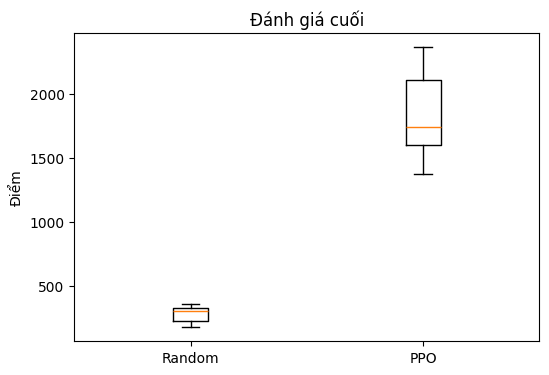

[play] ván 1: 1660 điểm (1088 bước)
[play] ván 2: 2110 điểm (1236 bước)


[1660.0, 2110.0]

In [2]:
from pacman_rl import evaluate, watch, dqn_policy
from pacman_rl.plotting import plot_eval
from pacman_rl import random_baseline
from pacman_rl.evaluation import ppo_policy
from pacman_rl import get_device
from pacman_rl.runs import load_run
device = get_device()
current_session = last_session
load_ppo = load_run("runs", f"{current_session}", "ppo", device=device)
act_ppo = ppo_policy(load_ppo.model, device)              # greedy=True: luôn chọn action tốt nhất

plot_eval({"Random": random_baseline(5),
           "PPO": evaluate(act_ppo, n_episodes=10),  # seed cố định 1000..1009, công bằng giữa các phương pháp
           })

watch(act_ppo, episodes=2)                           # mở cửa sổ game, cần màn hình


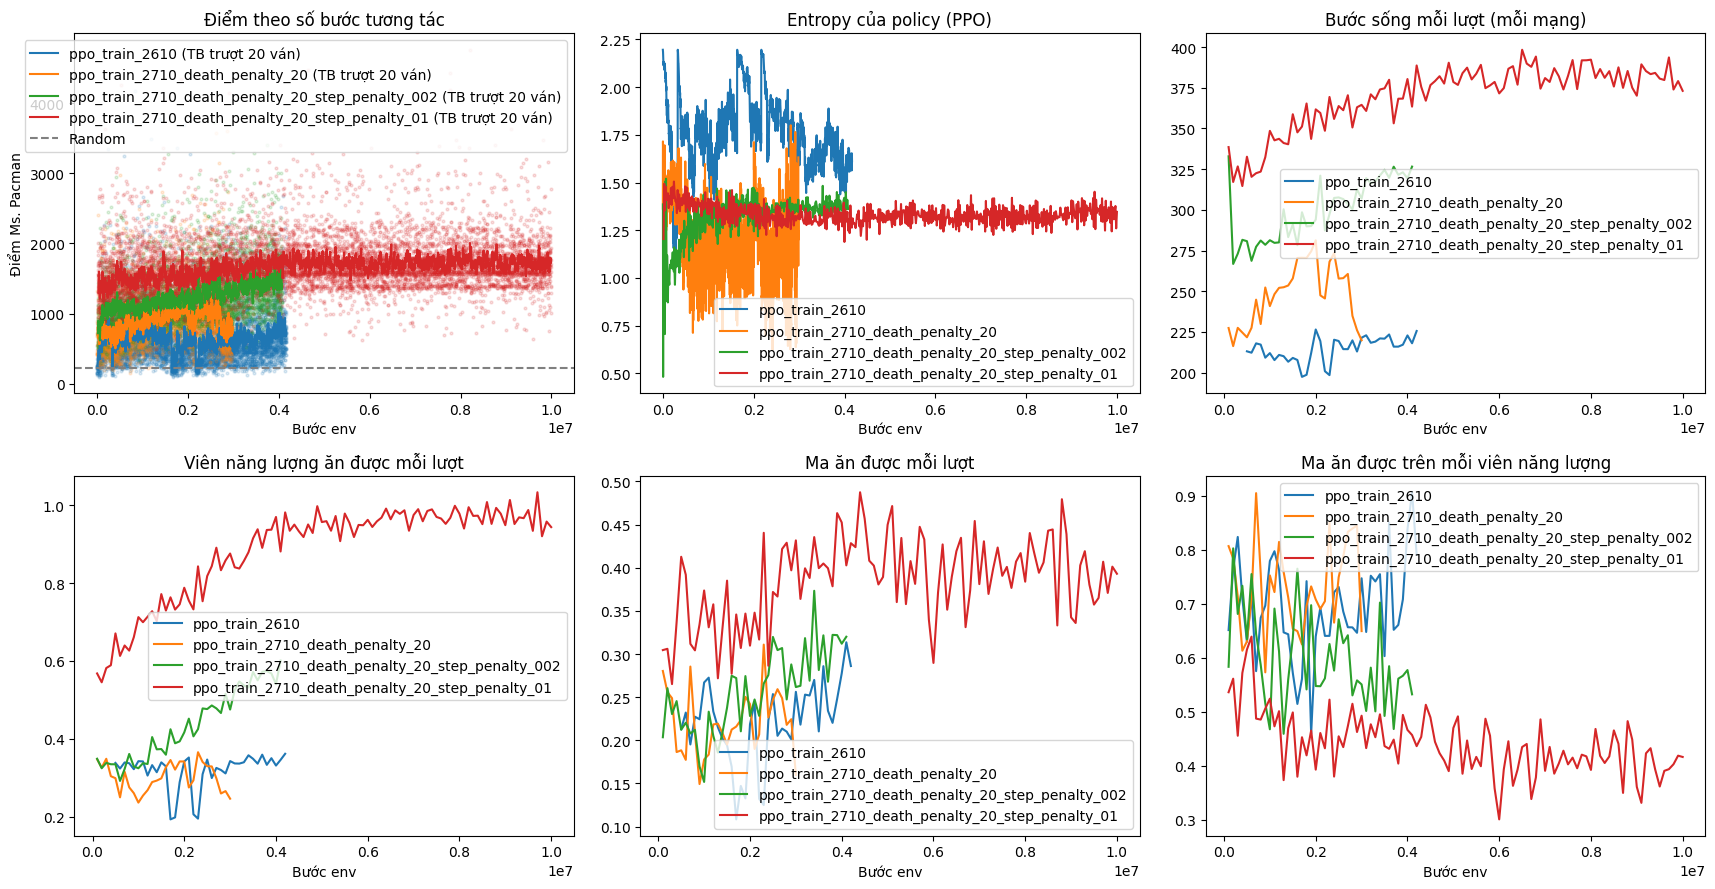

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


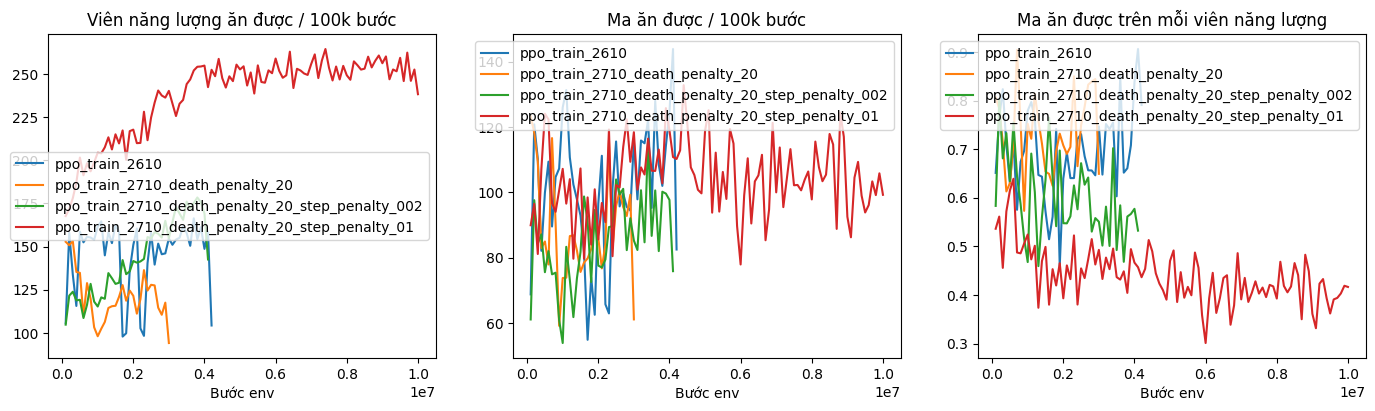

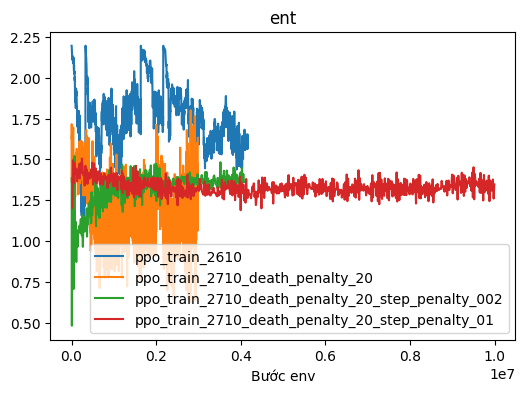

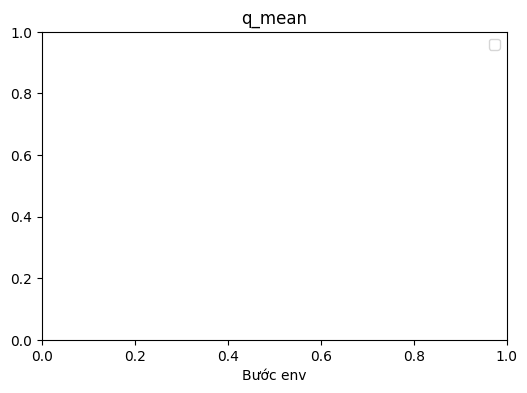

In [3]:
from pacman_rl.plotting import compare
from pacman_rl import random_baseline, get_device
device = get_device()
runs = compare(
    ["ppo_train_2610", 
     "ppo_train_2710_death_penalty_20",
     "ppo_train_2710_death_penalty_20_step_penalty_002",
     "ppo_train_2710_death_penalty_20_step_penalty_01"], 
               directory="runs",
               random_scores=random_baseline(5),
               metrics=("ent", "q_mean"),
               device=device,
               save_path="runs/27-10.png")